# RWA redemption analysis

This notebook analyzes the redeems in `redemptions.csv`. Each token has a separate section.

Data rules:

- The notebook uses only redeems with an `amount_usd` value of 100 USD or more.
- All times are in UTC.
- The "last 12 months" period ends with the month of the latest redeem in the data. This last month can be incomplete.
- The "average number of redeems" for a month is the number of redeems divided by the number of days in that month.
- For the last month, the notebook divides by the number of days up to the latest redeem.

## Setup

This cell loads the data, applies the 100 USD limit and defines the shared functions.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter, MaxNLocator

MIN_USD = 100
PERCENTILES = [0.20, 0.50, 0.95, 0.99]
TOKENS = ["USTB", "USCC", "mWIN"]
BAR_COLOR = "#2a78d6"

# The notebook lives in output/, next to the CSV. The second path works when the kernel starts at the repo root.
DATA = next(p for p in [Path("redemptions.csv"), Path("output/redemptions.csv")] if p.exists())

raw = pd.read_csv(DATA, parse_dates=["timestamp"])
df = raw[raw["amount_usd"] >= MIN_USD].copy()
utc = df["timestamp"].dt.tz_convert("UTC").dt.tz_localize(None)
df["month"] = utc.dt.to_period("M")
df["hour"] = utc.dt.hour

END = utc.max()
MONTHS = pd.period_range(END.to_period("M") - 11, END.to_period("M"), freq="M")
DAYS = pd.Series([m.days_in_month for m in MONTHS], index=MONTHS)
DAYS.iloc[-1] = END.day  # the last month counts only the days up to the latest redeem

missing = sorted(set(df["token"]) - set(TOKENS))
print(f"Rows in CSV: {len(raw):,}. Rows with amount_usd >= {MIN_USD} USD: {len(df):,}.")
print(f"Last 12 months: {MONTHS[0]} to {MONTHS[-1]} (data ends {END:%Y-%m-%d %H:%M} UTC).")
print(f"Tokens without a section: {missing or 'none'}")

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})


def usd(x, _pos=None):
    for div, suffix in ((1e9, "B"), (1e6, "M"), (1e3, "K")):
        if abs(x) >= div:
            return f"${x / div:,.1f}{suffix}"
    return f"${x:,.0f}"


def bar(labels, values, title, ylabel, money=False, integer=False):
    fig, ax = plt.subplots()
    ax.bar(labels, values, color=BAR_COLOR, width=0.7)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    if money:
        ax.yaxis.set_major_formatter(FuncFormatter(usd))
    if integer:
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    if isinstance(labels[0], str):  # month labels need rotation, hour numbers do not
        ax.tick_params(axis="x", labelrotation=45)
    else:
        ax.set_xticks(labels)
    fig.tight_layout()
    plt.show()


def token_rows(token):
    return df[df["token"] == token]


def overall(token):
    s = token_rows(token)["amount_usd"]
    stats = {"Redeems (count)": f"{len(s):,}", "Average": usd(s.mean()), "Std": usd(s.std()), "Min": usd(s.min())}
    for p in PERCENTILES:
        stats[f"P{p * 100:.0f}"] = usd(s.quantile(p))
    stats["Max"] = usd(s.max())
    display(pd.DataFrame({"Value": stats}))


def monthly(token):
    t = token_rows(token)
    g = t[t["month"].isin(MONTHS)].groupby("month")["amount_usd"]
    m = pd.DataFrame(index=MONTHS)
    m["redeems"] = g.size().reindex(MONTHS, fill_value=0)
    m["days"] = DAYS
    m["avg_redeems_per_day"] = m["redeems"] / m["days"]
    m["avg_amount_usd"] = g.mean().reindex(MONTHS)
    m["total_amount_usd"] = g.sum().reindex(MONTHS, fill_value=0)
    m["label"] = [p.strftime("%b %Y") for p in MONTHS]
    return m


def show_monthly_table(m):
    table = pd.DataFrame({
        "Redeems": m["redeems"],
        "Days": m["days"],
        "Avg redeems / day": m["avg_redeems_per_day"].map("{:.2f}".format),
        "Avg amount": m["avg_amount_usd"].map(lambda v: usd(v) if pd.notna(v) else "-"),
        "Total amount": m["total_amount_usd"].map(usd),
    })
    table.index = m["label"]
    display(table)


def hourly(token):
    return token_rows(token).groupby("hour").size().reindex(range(24), fill_value=0)

Rows in CSV: 12,346. Rows with amount_usd >= 100 USD: 10,178.
Last 12 months: 2025-12 to 2026-11 (data ends 2026-11-12 22:36 UTC).
Tokens without a section: none


## USTB (Superstate)

### USTB: overall

The table shows the number of redeems, the average redeem amount and the standard deviation (std).
It also shows the minimum redeem amount, the percentiles and the maximum redeem amount.
All values are in USD.

In [2]:
overall("USTB")

,Value
Redeems (count),"9,706"
Average,$638.6K
Std,$5.5M
Min,$100
P20,$1.4K
P50,$18.6K
P95,$2.0M
P99,$10.0M
Max,$303.1M


### USTB: last 12 months

The table shows the monthly values. Each chart below shows one monthly value.

In [3]:
m = monthly("USTB")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,355,31,11.45,$765.8K,$271.9M
Jan 2026,434,31,14.00,$270.9K,$117.6M
Feb 2026,641,28,22.89,$598.5K,$383.6M
Mar 2026,451,31,14.55,$1.0M,$465.4M
Apr 2026,216,30,7.20,$3.0M,$645.4M
May 2026,406,31,13.10,$1.3M,$547.6M
Jun 2026,636,30,21.20,$1.2M,$737.3M
Jul 2026,538,31,17.35,$467.6K,$251.6M
Aug 2026,685,31,22.10,$506.9K,$347.2M


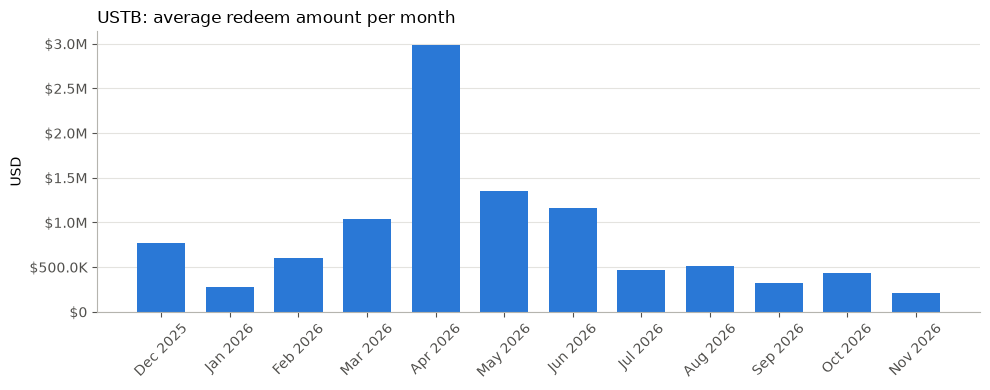

In [4]:
bar(m["label"].tolist(), m["avg_amount_usd"], "USTB: average redeem amount per month", "USD", money=True)

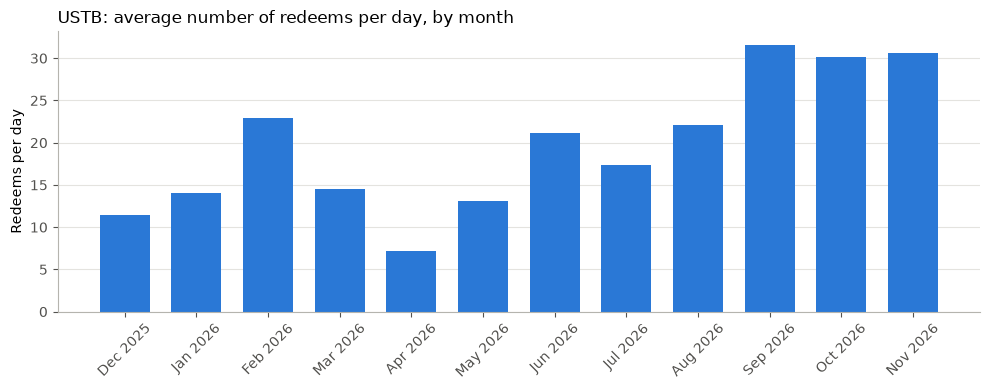

In [5]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "USTB: average number of redeems per day, by month", "Redeems per day")

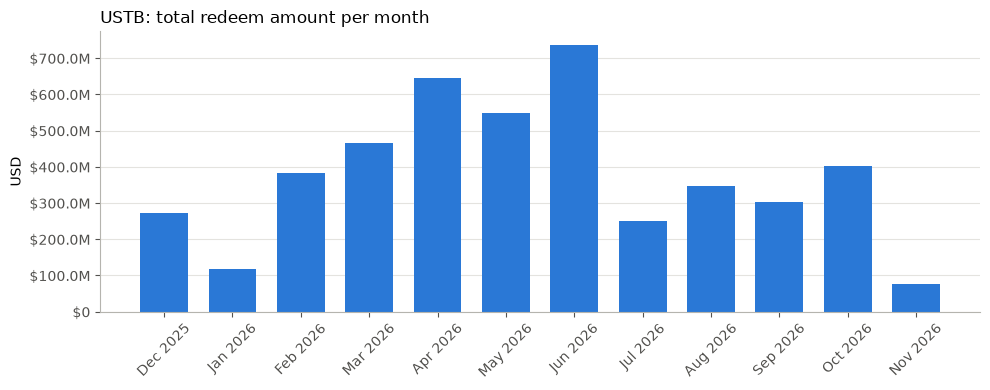

In [6]:
bar(m["label"].tolist(), m["total_amount_usd"], "USTB: total redeem amount per month", "USD", money=True)

### USTB: redeems by hour of the day

The chart shows the number of redeems in each hour of the day (UTC). It uses all the data, not only the last 12 months.

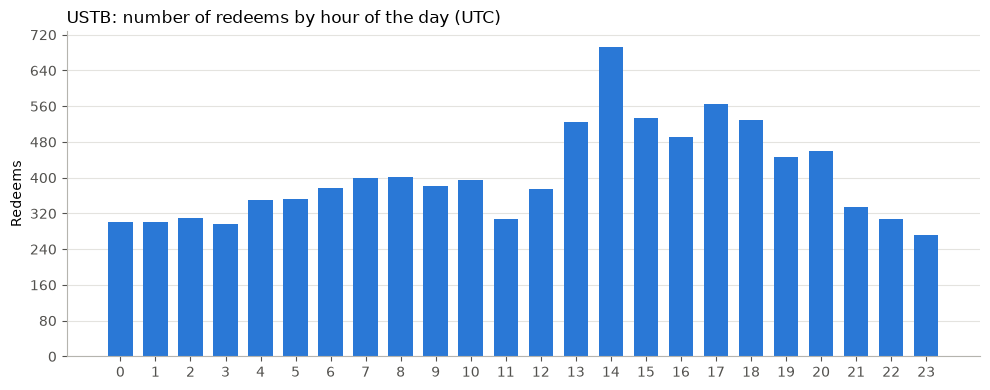

In [7]:
h = hourly("USTB")
bar(h.index.tolist(), h.values, "USTB: number of redeems by hour of the day (UTC)", "Redeems", integer=True)

## USCC (Superstate)

### USCC: overall

The table shows the number of redeems, the average redeem amount and the standard deviation (std).
It also shows the minimum redeem amount, the percentiles and the maximum redeem amount.
All values are in USD.

In [8]:
overall("USCC")

,Value
Redeems (count),428
Average,$2.4M
Std,$5.7M
Min,$107
P20,$8.8K
P50,$502.8K
P95,$11.1M
P99,$32.6M
Max,$50.3M


### USCC: last 12 months

The table shows the monthly values. Each chart below shows one monthly value.

In [9]:
m = monthly("USCC")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,23,31,0.74,$8.9M,$204.5M
Jan 2026,37,31,1.19,$3.5M,$128.2M
Feb 2026,40,28,1.43,$2.5M,$102.0M
Mar 2026,20,31,0.65,$1.4M,$28.6M
Apr 2026,25,30,0.83,$1.4M,$34.7M
May 2026,20,31,0.65,$1.9M,$38.6M
Jun 2026,60,30,2.00,$1.2M,$72.0M
Jul 2026,36,31,1.16,$1.4M,$49.2M
Aug 2026,8,31,0.26,$885.6K,$7.1M


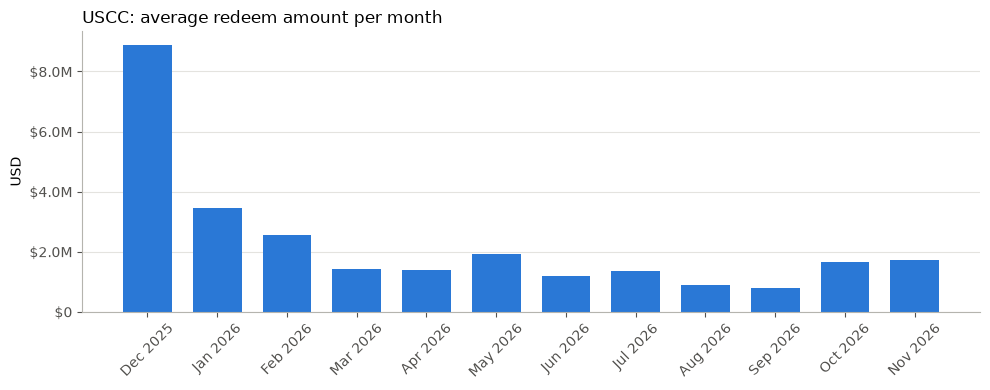

In [10]:
bar(m["label"].tolist(), m["avg_amount_usd"], "USCC: average redeem amount per month", "USD", money=True)

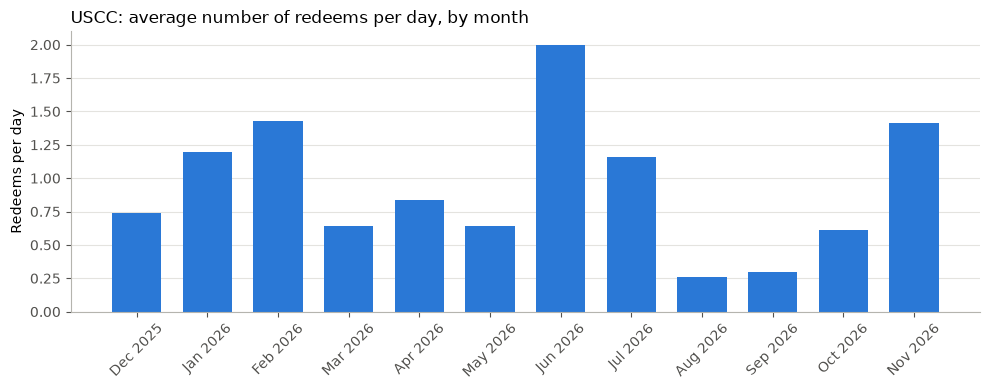

In [11]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "USCC: average number of redeems per day, by month", "Redeems per day")

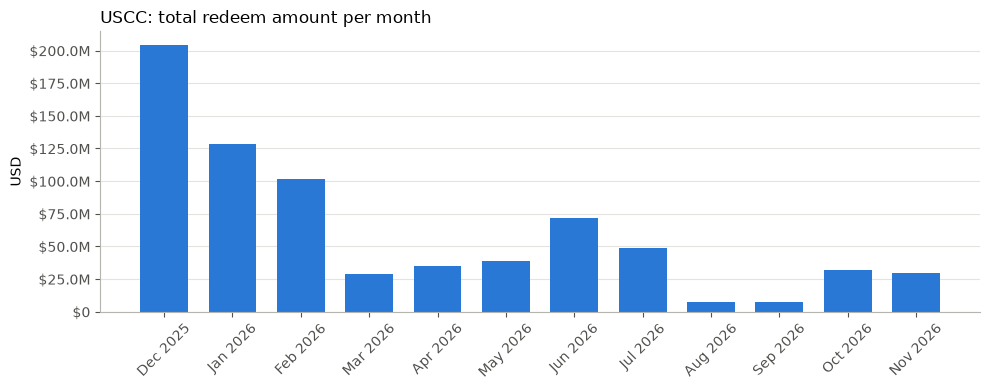

In [12]:
bar(m["label"].tolist(), m["total_amount_usd"], "USCC: total redeem amount per month", "USD", money=True)

### USCC: redeems by hour of the day

The chart shows the number of redeems in each hour of the day (UTC). It uses all the data, not only the last 12 months.

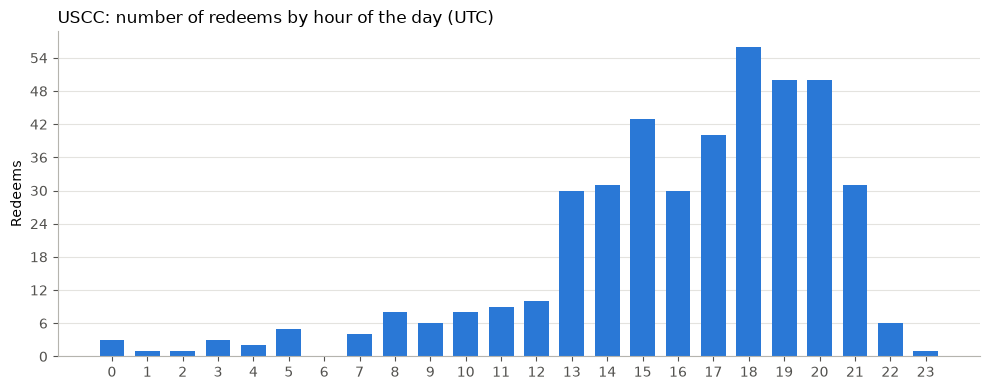

In [13]:
h = hourly("USCC")
bar(h.index.tolist(), h.values, "USCC: number of redeems by hour of the day (UTC)", "Redeems", integer=True)

## mWIN (Midas)

### mWIN: overall

The table shows the number of redeems, the average redeem amount and the standard deviation (std).
It also shows the minimum redeem amount, the percentiles and the maximum redeem amount.
All values are in USD.

In [14]:
overall("mWIN")

,Value
Redeems (count),44
Average,$870.5K
Std,$1.1M
Min,$523
P20,$159.4K
P50,$510.2K
P95,$3.5M
P99,$3.9M
Max,$3.9M


### mWIN: last 12 months

The table shows the monthly values. Each chart below shows one monthly value.

In [15]:
m = monthly("mWIN")
show_monthly_table(m)

,Redeems,Days,Avg redeems / day,Avg amount,Total amount
label,,,,,
Dec 2025,0,31,0.00,-,$0
Jan 2026,0,31,0.00,-,$0
Feb 2026,0,28,0.00,-,$0
Mar 2026,0,31,0.00,-,$0
Apr 2026,0,30,0.00,-,$0
May 2026,0,31,0.00,-,$0
Jun 2026,0,30,0.00,-,$0
Jul 2026,0,31,0.00,-,$0
Aug 2026,4,31,0.13,$392.1K,$1.6M


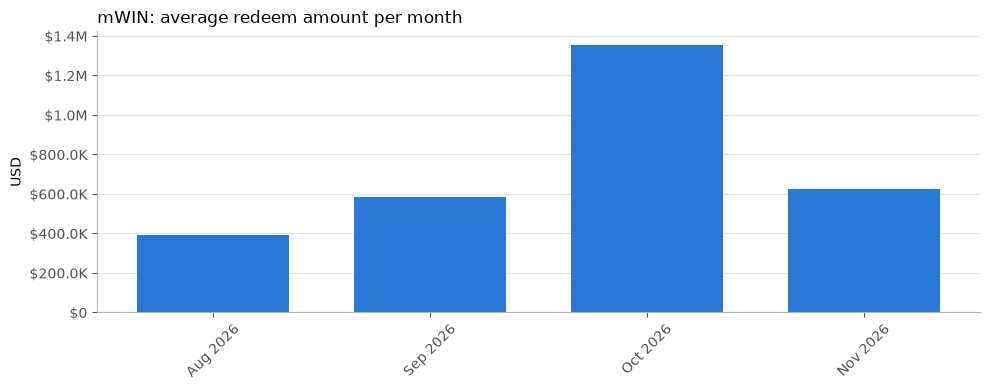

In [16]:
bar(m["label"].tolist(), m["avg_amount_usd"], "mWIN: average redeem amount per month", "USD", money=True)

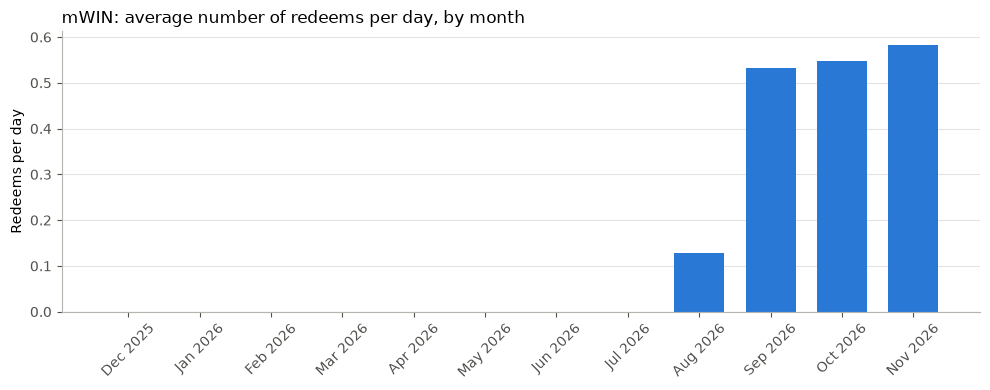

In [17]:
bar(m["label"].tolist(), m["avg_redeems_per_day"], "mWIN: average number of redeems per day, by month", "Redeems per day")

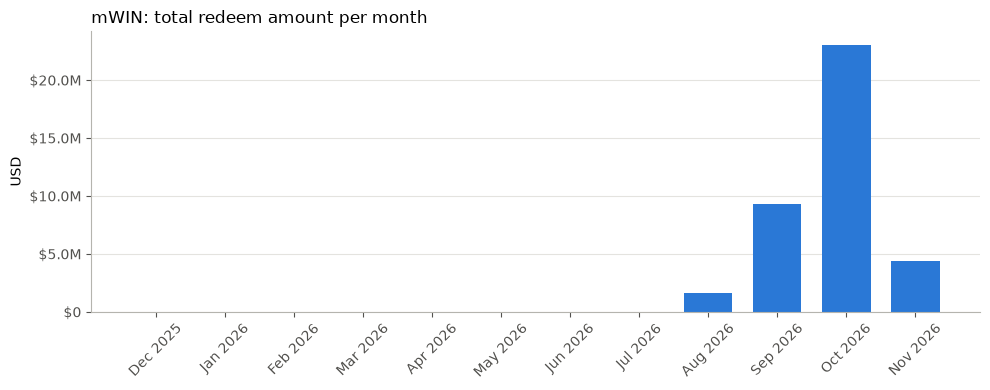

In [18]:
bar(m["label"].tolist(), m["total_amount_usd"], "mWIN: total redeem amount per month", "USD", money=True)

### mWIN: redeems by hour of the day

The chart shows the number of redeems in each hour of the day (UTC). It uses all the data, not only the last 12 months.

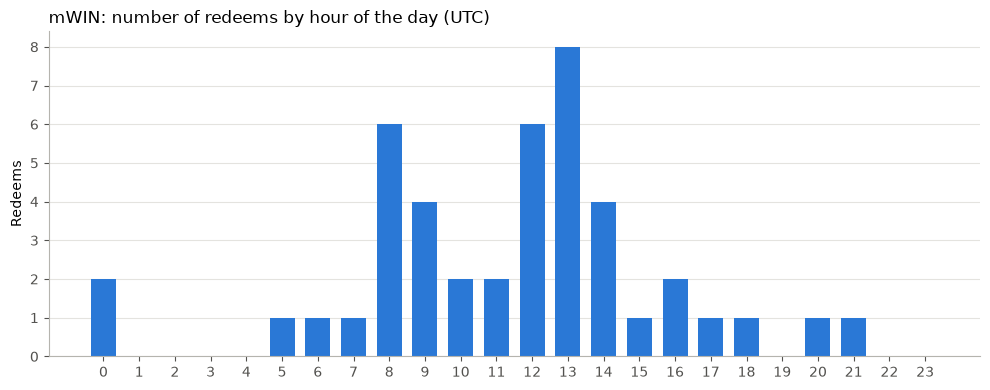

In [19]:
h = hourly("mWIN")
bar(h.index.tolist(), h.values, "mWIN: number of redeems by hour of the day (UTC)", "Redeems", integer=True)